# RegimeLens — Train-Frozen HMM & Chronological Evaluation
# HMM cố định trên train và đánh giá theo thời gian

**Trương Minh Hoàng · MSSV 25410008 · UIT Big Data group project**

Tôi nghiên cứu dự đoán trạng thái thị trường ngày kế tiếp với HMM ba trạng thái.
Scaler/HMM học trên train; forward filtering sử dụng quan sát đến ngày đang xét.
Tôi so sánh Logistic Regression, Random Forest và XGBoost với đối chứng persistence.

This notebook evaluates next-day prediction of a fitted HMM's latent states with a chronological split.
Set `REGIMELENS_DATA_DIR` to the original CSV directory. Without it, the notebook runs a separately labeled synthetic example.


In [1]:
from pathlib import Path
import os, sys, json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from chronological_experiment import build_market,run_experiment,FEATURES
if os.environ.get('REGIMELENS_DATA_DIR'):
    market,data_audit=build_market(os.environ['REGIMELENS_DATA_DIR']);source='ORIGINAL_CSV_SNAPSHOT'
else:
    rng=np.random.default_rng(42);n=1200
    state=np.repeat([0,1,2,1],300)
    synthetic=rng.normal(size=(n,7))*.3+np.array([-1,0,1])[state,None]
    market=pd.DataFrame(synthetic,columns=FEATURES);market['date']=pd.bdate_range('2020-01-01',periods=n)
    data_audit={'source':'synthetic only','usable_market_days':n};source='SYNTHETIC_SMOKE'
print('Source:',source,'Market days:',len(market))
display(pd.Series(data_audit))


Source: ORIGINAL_CSV_SNAPSHOT Market days: 6374


source_sha256         {'SP500_Historical_Data.csv': 'c64ea2c045f6104...
source_stock_rows                                               2087863
usable_market_days                                                 6374
universe              tickers supplied in source export; historical ...
dtype: object

## 1. Ranh giới thời gian / Information boundaries
70% ngày đầu dùng cho fit scaler/HMM và supervised training; 15% tiếp chọn mô hình, 15% cuối báo cáo test. Mỗi cặp (feature t, target t+1) nằm trọn trong một giai đoạn. Giữ cố định 3 trạng thái như mã nhóm được tìm thấy; chưa gán tên kinh tế cho từng state.

In [2]:
result,probabilities,states,test_index,y=run_experiment(market)
result['data_source']=source;result['data_audit']=data_audit
display(pd.DataFrame(result['periods']).T)
print('Future-perturbation invariance:',result['causal_filter_future_perturbation_test'])
assert result['causal_filter_future_perturbation_test']


,first_feature_date,last_target_date
train,2000-10-16,2018-07-11
validation,2018-07-12,2022-04-27
test,2022-04-28,2026-02-20


Future-perturbation invariance: True


## 2. So sánh với persistence / Compare with persistence
Chọn theo macro F1 trên validation. Bảng test được tính sau bước chọn; không refit hoặc đổi nhãn HMM theo validation/test. Macro F1 dùng đủ 3 nhãn, kể cả khi một giai đoạn không xuất hiện một trạng thái.

In [3]:
validation=pd.DataFrame(result['validation_metrics'])
test=pd.DataFrame(result['test_metrics'])
display(validation[['model','accuracy','macro_f1']].round(5))
print('Selected using validation:',result['selected_using_validation'])
display(test[['model','accuracy','macro_f1']].round(5))


,model,accuracy,macro_f1
0,Persistence,0.94241,0.93391
1,Logistic Regression,0.94031,0.93208
2,Random Forest,0.94974,0.94122
3,XGBoost,0.94555,0.93553


Selected using validation: Random Forest


,model,accuracy,macro_f1
0,Persistence,0.93724,0.93073
1,Logistic Regression,0.93619,0.92932
2,Random Forest,0.95084,0.94392
3,XGBoost,0.93619,0.92789


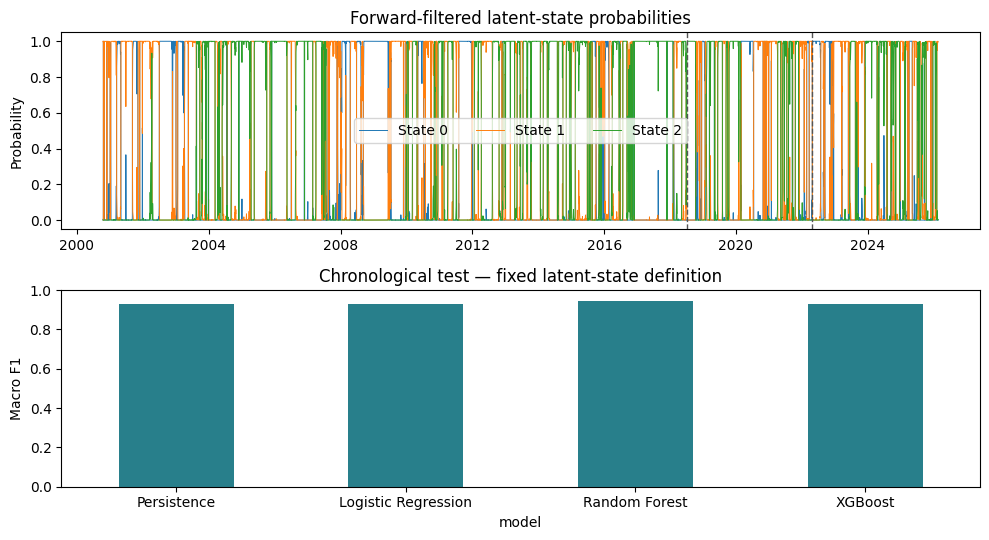

In [4]:
fig,ax=plt.subplots(2,1,figsize=(10,5.5))
for state in range(3):ax[0].plot(market.date,probabilities[:,state],label=f'State {state}',linewidth=.7)
ax[0].set(title='Forward-filtered latent-state probabilities',ylabel='Probability')
ax[0].legend(ncol=3)
for key in ['validation','test']:
    ax[0].axvline(pd.Timestamp(result['periods'][key]['first_feature_date']),color='#555',linestyle='--',linewidth=1)
test.set_index('model').macro_f1.plot.bar(ax=ax[1],color='#287f8b',rot=0)
ax[1].set(title='Chronological test — fixed latent-state definition',ylabel='Macro F1',ylim=(0,1))
fig.tight_layout();plt.show()


## 3. Giới hạn còn lại / Remaining limits
Chỉ một phép chia thời gian và một seed. HMM là nguồn nhãn, không phải nhãn kinh tế độc lập. Universe trong file nguồn chưa tái dựng thành phần S&P 500 theo ngày; dữ liệu điều chỉnh và thời điểm công bố VIX cần được thẩm định thêm. Không có backtest, phí hay slippage trong kết quả này. Multi-window evaluation là bước tiếp theo.

In [5]:
from datetime import datetime,timezone
LAB_RESULT={**result,'completed_at_utc':datetime.now(timezone.utc).isoformat()}
(ROOT/'evidence').mkdir(exist_ok=True)
name='chronological_experiment.json' if source=='ORIGINAL_CSV_SNAPSHOT' else 'synthetic_smoke.json'
(ROOT/'evidence'/name).write_text(json.dumps(LAB_RESULT,indent=2,ensure_ascii=False)+'\n')
print('Saved evidence/'+name)


Saved evidence/chronological_experiment.json
